In [533]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, LearningCurveDisplay
from sklearn.pipeline import make_pipeline
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import ElasticNet
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, mean_absolute_percentage_error

In [534]:
df = pd.read_csv('housing_dataset.csv')
display(df.head())
df.info()

,HouseSize,DistanceToCity,Location,Price
0,NaN,22.92,B,20.74
1,48.6,27.90,B,19.35
2,NaN,28.29,A,23.30
3,65.2,25.99,A,25.37
4,47.7,29.19,A,19.66


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   HouseSize       95 non-null     float64
 1   DistanceToCity  95 non-null     float64
 2   Location        95 non-null     object 
 3   Price           100 non-null    float64
dtypes: float64(3), object(1)
memory usage: 3.2+ KB


In [535]:
y = df['Price']
X = df.drop(columns=['Price'])

In [536]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [537]:
scaler = StandardScaler()
num_preprocessor = make_pipeline(KNNImputer(), scaler)

cat_imputer = SimpleImputer(strategy='most_frequent')
encoder = OneHotEncoder(drop='first')
cat_preprocessor = make_pipeline(cat_imputer, encoder)

preprocessor = ColumnTransformer([
    ('numerical', num_preprocessor, ['HouseSize', 'DistanceToCity']),
    ('categorical', cat_preprocessor, ['Location'])
])

In [538]:
model = ElasticNet(random_state=42)
pipeline = make_pipeline(preprocessor, model)
pipeline

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('knnimputer',
                                                                   KNNImputer()),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['HouseSize',
                                                   'DistanceToCity']),
                                                 ('categorical',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(drop='first'))]),
                                                  ['Location'])])),
                ('elasticnet', ElasticNet(random_state=42))])

In [539]:
param_grid = {
   'elasticnet__alpha': np.logspace(-2, 1, 10),
   'elasticnet__l1_ratio': [0.25, 0.5, 0.75]
}

grid_cv = GridSearchCV(estimator=pipeline, param_grid=param_grid, scoring='neg_mean_absolute_percentage_error')

grid_cv.fit(X_train, y_train)

GridSearchCV(estimator=Pipeline(steps=[('columntransformer',
                                        ColumnTransformer(transformers=[('numerical',
                                                                         Pipeline(steps=[('knnimputer',
                                                                                          KNNImputer()),
                                                                                         ('standardscaler',
                                                                                          StandardScaler())]),
                                                                         ['HouseSize',
                                                                          'DistanceToCity']),
                                                                        ('categorical',
                                                                         Pipeline(steps=[('simpleimputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('onehotencoder',
                                                                                          OneHotEncoder(drop='first'))]),
                                                                         ['Location'])])),
                                       ('elasticnet',
                                        ElasticNet(random_state=42))]),
             param_grid={'elasticnet__alpha': array([ 0.01      ,  0.02154435,  0.04641589,  0.1       ,  0.21544347,
        0.46415888,  1.        ,  2.15443469,  4.64158883, 10.        ]),
                         'elasticnet__l1_ratio': [0.25, 0.5, 0.75]},
             scoring='neg_mean_absolute_percentage_error')

In [540]:
grid_cv.best_params_, -grid_cv.best_score_

({'elasticnet__alpha': np.float64(0.021544346900318832),
  'elasticnet__l1_ratio': 0.75},
 np.float64(0.04351739001962267))

In [541]:
best_model = grid_cv.best_estimator_
y_pred = best_model.predict(X_test).ravel()
r2_score(y_true=y_test, y_pred=y_pred), mean_absolute_percentage_error(y_true=y_test, y_pred=y_pred)

(0.7464363118322466, 0.05073194612288577)

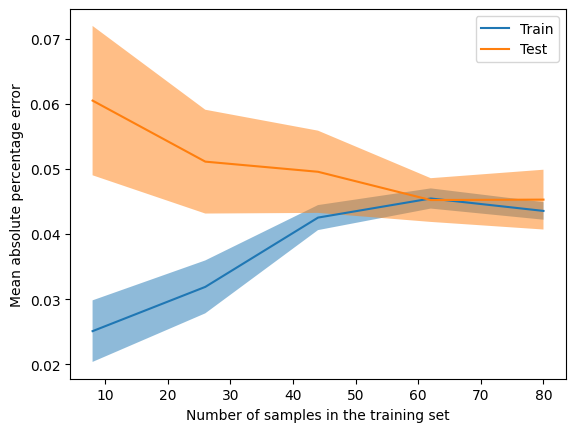

In [542]:
LearningCurveDisplay.from_estimator(
    estimator=best_model,
    X=X,
    y=y,
    scoring='neg_mean_absolute_percentage_error',
    negate_score=True
)

Text(0, 0.5, 'y_test')

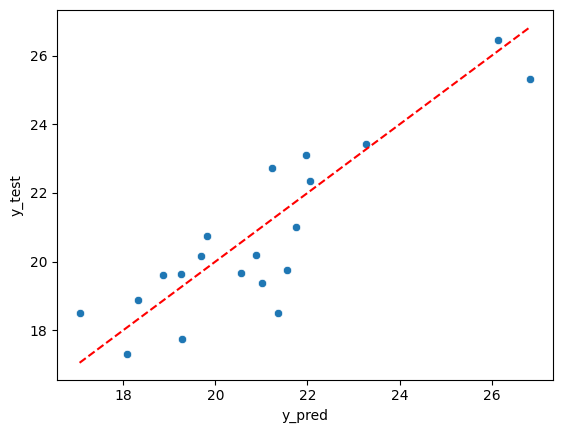

In [543]:
sns.scatterplot(x=y_pred, y=y_test)

min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--')

plt.xlabel('y_pred')
plt.ylabel('y_test')